<a href="https://colab.research.google.com/github/vanshkothare/Machine-learning-5th-SEM-project/blob/main/Smart_Traffic_Management_Using_AIML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
data = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", data.shape)
display(data.head())
print("Columns:", data.columns.tolist())

Saving smart_traffic_management_dataset.csv to smart_traffic_management_dataset.csv
Dataset loaded successfully!
Dataset Shape: (2000, 12)


,timestamp,location_id,traffic_volume,avg_vehicle_speed,vehicle_count_cars,vehicle_count_trucks,vehicle_count_bikes,weather_condition,temperature,humidity,accident_reported,signal_status
0,2024-01-01 00:00:00,4,504,53.124162,142,24,44,Cloudy,33.334387,36.390698,0,Red
1,2024-01-01 00:01:00,5,209,44.947850,862,50,23,Cloudy,17.926830,37.640927,0,Green
2,2024-01-01 00:02:00,3,572,63.179229,317,12,10,Windy,33.483375,84.262610,1,Red
3,2024-01-01 00:03:00,5,699,42.269697,709,43,21,Sunny,19.212941,61.550978,0,Yellow
4,2024-01-01 00:04:00,5,639,72.185791,594,34,14,Cloudy,11.349244,77.494506,0,Red


Columns: ['timestamp', 'location_id', 'traffic_volume', 'avg_vehicle_speed', 'vehicle_count_cars', 'vehicle_count_trucks', 'vehicle_count_bikes', 'weather_condition', 'temperature', 'humidity', 'accident_reported', 'signal_status']


In [3]:
print("Missing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

data = data.drop_duplicates().copy()
data = data.dropna(axis=1, how="all")

print("\nDataset after cleaning:", data.shape)
print("\nColumn names:")
print(data.columns.tolist())

Missing values:
timestamp               0
location_id             0
traffic_volume          0
avg_vehicle_speed       0
vehicle_count_cars      0
vehicle_count_trucks    0
vehicle_count_bikes     0
weather_condition       0
temperature             0
humidity                0
accident_reported       0
signal_status           0
dtype: int64

Duplicate rows: 0

Dataset after cleaning: (2000, 12)

Column names:
['timestamp', 'location_id', 'traffic_volume', 'avg_vehicle_speed', 'vehicle_count_cars', 'vehicle_count_trucks', 'vehicle_count_bikes', 'weather_condition', 'temperature', 'humidity', 'accident_reported', 'signal_status']


In [5]:
target_candidates = [
    "signal_status",
    "accident_reported",
    "Traffic_Level",
    "Traffic_Status",
    "Traffic_Situation",
    "Traffic Situation",
    "traffic_level",
    "traffic_status",
    "traffic_situation",
    "traffic_condition",
    "Congestion_Level",
    "congestion_level",
    "target",
    "Target",
    "class",
    "Class"
]

target_col = next(
    (col for col in target_candidates if col in data.columns),
    None
)

if target_col is None:
    raise ValueError(
        "Target column automatically nahi mila. "
        "Step 2 ke column names dekhkar target_col set karo."
    )

print("Target column:", target_col)
print(data[target_col].value_counts())

# Rows without target labels cannot train a classifier
data = data.dropna(subset=[target_col]).copy()

X = data.drop(columns=[target_col])
y = data[target_col].astype(str)

# Remove columns that act like unique IDs
id_cols = [
    col for col in X.columns
    if col.lower() in ["id", "row_id", "record_id"]
]
X = X.drop(columns=id_cols)

# Convert dates into useful numeric features
for col in X.columns:
    if "date" in col.lower() or "time" in col.lower():
        parsed = pd.to_datetime(X[col], errors="coerce")
        if parsed.notna().mean() > 0.7:
            X[col + "_year"] = parsed.dt.year
            X[col + "_month"] = parsed.dt.month
            X[col + "_day"] = parsed.dt.day
            X[col + "_hour"] = parsed.dt.hour
            X = X.drop(columns=[col])

# Encode text features
X = pd.get_dummies(X, dummy_na=True)

# Remove infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns with no usable values
X = X.dropna(axis=1, how="all")

print("Features shape:", X.shape)
print("Target classes:", y.nunique())

Target column: signal_status
signal_status
Yellow    708
Red       683
Green     609
Name: count, dtype: int64
Features shape: (2000, 19)
Target classes: 3


In [6]:
if y.nunique() < 2:
    raise ValueError("Classification ke liye minimum 2 target classes chahiye.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "Decision Tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(random_state=42)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=150,
            random_state=42,
            n_jobs=-1
        )
    ),

    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC()
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingClassifier(random_state=42)
    )
}

results = []
trained_models = {}

for name, model in models.items():
    try:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)

        results.append({
            "Algorithm": name,
            "Accuracy (%)": round(accuracy * 100, 2)
        })

        trained_models[name] = model

        print(f"{name}: {accuracy * 100:.2f}%")

    except Exception as e:
        print(f"{name} failed: {e}")

results_df = pd.DataFrame(results).sort_values(
    "Accuracy (%)", ascending=False
)

print("\nAlgorithm Comparison:")
display(results_df)

Logistic Regression: 36.00%
Decision Tree: 34.50%
Random Forest: 33.00%
KNN: 37.00%
SVM: 34.00%
Gradient Boosting: 33.75%

Algorithm Comparison:


,Algorithm,Accuracy (%)
3,KNN,37.00
0,Logistic Regression,36.00
1,Decision Tree,34.50
4,SVM,34.00
5,Gradient Boosting,33.75
2,Random Forest,33.00


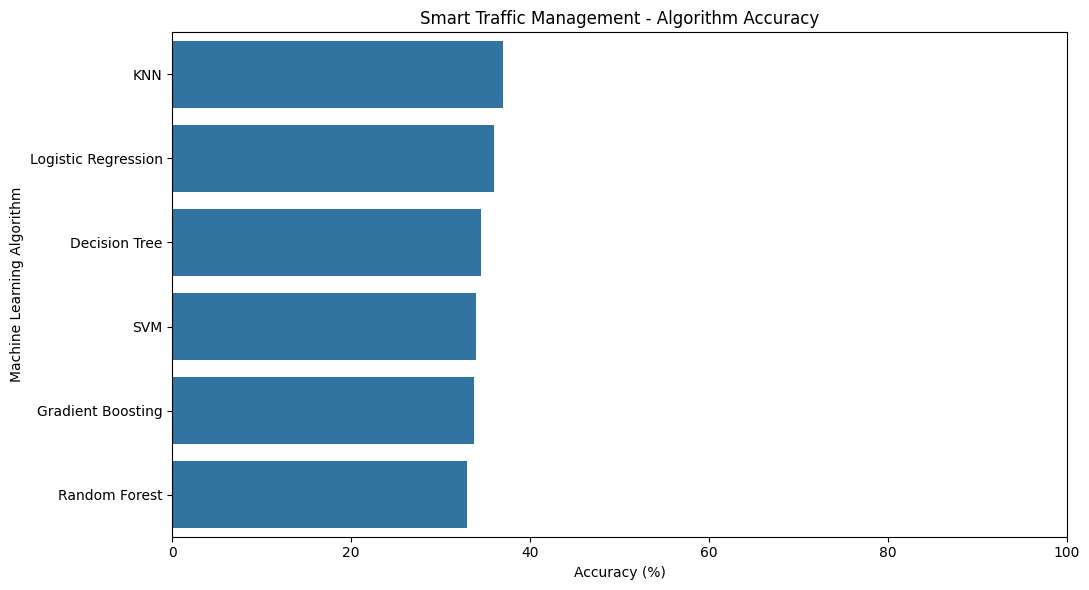

In [7]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Accuracy (%)",
    y="Algorithm"
)

plt.title("Smart Traffic Management - Algorithm Accuracy")
plt.xlabel("Accuracy (%)")
plt.ylabel("Machine Learning Algorithm")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

Best model: KNN

Classification Report:

              precision    recall  f1-score   support

       Green       0.32      0.45      0.37       122
         Red       0.39      0.40      0.40       136
      Yellow       0.44      0.27      0.33       142

    accuracy                           0.37       400
   macro avg       0.38      0.37      0.37       400
weighted avg       0.39      0.37      0.37       400



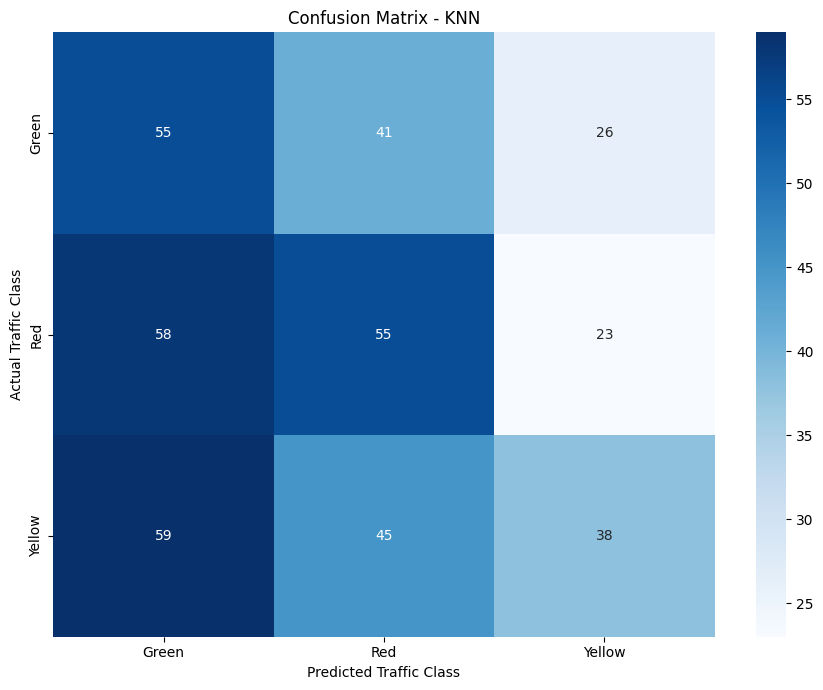

In [8]:
if not trained_models:
    raise ValueError("Koi model successfully train nahi hua.")

best_name = results_df.iloc[0]["Algorithm"]
best_model = trained_models[best_name]

best_predictions = best_model.predict(X_test)

print("Best model:", best_name)
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

labels = best_model.classes_

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=labels
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted Traffic Class")
plt.ylabel("Actual Traffic Class")
plt.tight_layout()
plt.show()

In [14]:
!pip -q install streamlit plotly scikit-learn pandas numpy

In [15]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

st.set_page_config(
    page_title="Smart Traffic AI",
    page_icon="🚦",
    layout="wide"
)

st.markdown("""
<style>
.stApp {background:#0b1220; color:#f1f5f9;}
[data-testid="stSidebar"] {background:#152238;}
[data-testid="stMetric"] {
    background:#172b45;
    padding:16px;
    border-radius:12px;
}
h1,h2,h3 {color:#42d9ff;}
</style>
""", unsafe_allow_html=True)

st.title("🚦 Smart Traffic Management Using AI")
st.caption("AI-powered traffic analytics and prediction dashboard")

# ---------------- SIDEBAR ----------------
st.sidebar.title("Navigation")
page = st.sidebar.radio(
    "Select Page",
    ["Dashboard", "Traffic Prediction", "ML Algorithms", "Dataset Explorer"]
)

uploaded = st.sidebar.file_uploader("Upload Kaggle CSV", type=["csv"])

if uploaded is None:
    st.info("👈 Sidebar mein apni Kaggle CSV upload karo.")
    st.markdown("""
    ### Dashboard features
    - Traffic dataset analysis
    - Six ML algorithms comparison
    - Traffic class prediction
    - Confusion matrix
    - Dataset explorer
    """)
    st.stop()

try:
    data = pd.read_csv(uploaded)
except Exception as e:
    st.error(f"CSV read error: {e}")
    st.stop()

if data.empty:
    st.error("CSV file empty hai.")
    st.stop()

# Remove duplicate rows
data = data.drop_duplicates().copy()

# ---------------- SELECT TARGET ----------------
target_candidates = [
    "Traffic_Level", "Traffic_Status", "Traffic_Situation",
    "Traffic Situation", "traffic_level", "traffic_status",
    "traffic_situation", "Traffic Condition", "traffic_condition",
    "Congestion_Level", "congestion_level", "target", "Target",
    "class", "Class"
]

default_target = next(
    (c for c in target_candidates if c in data.columns),
    data.columns[-1]
)

target = st.sidebar.selectbox(
    "Target column (what to predict)",
    data.columns.tolist(),
    index=data.columns.tolist().index(default_target)
)

# ---------------- PREPROCESSING ----------------
def prepare_X(frame, target_col):
    X = frame.drop(columns=[target_col]).copy()

    # Remove ID fields
    id_cols = [
        c for c in X.columns
        if c.lower() in ["id", "row_id", "record_id"]
    ]
    X = X.drop(columns=id_cols)

    # Extract features from date/time fields
    for col in list(X.columns):
        if "date" in col.lower() or "time" in col.lower():
            dt = pd.to_datetime(X[col], errors="coerce")
            if dt.notna().mean() > 0.7:
                X[col + "_year"] = dt.dt.year
                X[col + "_month"] = dt.dt.month
                X[col + "_day"] = dt.dt.day
                X[col + "_hour"] = dt.dt.hour
                X = X.drop(columns=[col])

    X = pd.get_dummies(X, dummy_na=True)
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.dropna(axis=1, how="all")
    return X

def make_models():
    return {
        "Logistic Regression": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(max_iter=2000)
        ),
        "Decision Tree": make_pipeline(
            SimpleImputer(strategy="median"),
            DecisionTreeClassifier(random_state=42)
        ),
        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(
                n_estimators=100, random_state=42, n_jobs=-1
            )
        ),
        "KNN": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5)
        ),
        "SVM": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            SVC()
        ),
        "Gradient Boosting": make_pipeline(
            SimpleImputer(strategy="median"),
            GradientBoostingClassifier(random_state=42)
        )
    }

# Keep trained results across Streamlit reruns
if "training_key" not in st.session_state:
    st.session_state.training_key = None
    st.session_state.trained = None

training_key = (uploaded.name, target, len(data), tuple(data.columns))

# ---------------- DASHBOARD ----------------
if page == "Dashboard":
    st.subheader("📊 Traffic Dashboard")

    a, b, c, d = st.columns(4)
    a.metric("Total Records", f"{len(data):,}")
    b.metric("Total Features", len(data.columns) - 1)
    c.metric("Traffic Classes", data[target].nunique())
    d.metric("Missing Values", int(data.isnull().sum().sum()))

    st.markdown("### Traffic Class Distribution")

    counts = data[target].astype(str).value_counts().reset_index()
    counts.columns = ["Traffic Class", "Count"]

    fig = px.bar(
        counts,
        x="Traffic Class",
        y="Count",
        color="Traffic Class",
        template="plotly_dark",
        title="Traffic Class Distribution"
    )
    st.plotly_chart(fig, use_container_width=True)

    st.markdown("### Dataset Preview")
    st.dataframe(data.head(10), use_container_width=True)

    st.info(
        "Ye dataset-based demo hai. Live cameras aur actual "
        "traffic signals connected nahi hain."
    )

# ---------------- TRAFFIC PREDICTION ----------------
elif page == "Traffic Prediction":
    st.subheader("🤖 Traffic Prediction")

    st.write("Pehle ML Algorithms page se models train karo.")

    if st.session_state.trained is None:
        st.warning("Abhi models train nahi hue.")
    else:
        bundle = st.session_state.trained

        row_no = st.number_input(
            "Select dataset record",
            min_value=0,
            max_value=len(data) - 1,
            value=0,
            step=1
        )

        st.dataframe(data.iloc[[int(row_no)]], use_container_width=True)

        if st.button("Predict Traffic", type="primary"):
            raw = data.iloc[[int(row_no)]].drop(columns=[target])
            raw = raw.copy()

            for col in list(raw.columns):
                if "date" in col.lower() or "time" in col.lower():
                    dt = pd.to_datetime(raw[col], errors="coerce")
                    if dt.notna().mean() > 0.7:
                        raw[col + "_year"] = dt.dt.year
                        raw[col + "_month"] = dt.dt.month
                        raw[col + "_day"] = dt.dt.day
                        raw[col + "_hour"] = dt.dt.hour
                        raw = raw.drop(columns=[col])

            raw = raw.drop(
                columns=[
                    c for c in raw.columns
                    if c.lower() in ["id", "row_id", "record_id"]
                ],
                errors="ignore"
            )
            raw = pd.get_dummies(raw, dummy_na=True)
            raw = raw.replace([np.inf, -np.inf], np.nan)
            raw = raw.reindex(
                columns=bundle["features"], fill_value=0
            )

            prediction = bundle["best_model"].predict(raw)[0]
            st.success(f"Predicted Traffic Class: {prediction}")

            if hasattr(bundle["best_model"], "predict_proba"):
                try:
                    probs = bundle["best_model"].predict_proba(raw)[0]
                    prob_df = pd.DataFrame({
                        "Class": bundle["best_model"].classes_,
                        "Probability (%)": probs * 100
                    }).sort_values("Probability (%)", ascending=False)

                    fig = px.bar(
                        prob_df, x="Class", y="Probability (%)",
                        template="plotly_dark",
                        title="Prediction Probability"
                    )
                    st.plotly_chart(fig, use_container_width=True)
                except Exception:
                    pass

# ---------------- ALGORITHM COMPARISON ----------------
elif page == "ML Algorithms":
    st.subheader("🧠 Compare Six ML Algorithms")

    st.write("Target selected:", target)

    if st.button("Train and Compare", type="primary"):
        work = data.dropna(subset=[target]).copy()
        y = work[target].astype(str)

        if y.nunique() < 2:
            st.error("Target column mein kam se kam 2 classes honi chahiye.")
            st.stop()

        X = prepare_X(work, target)

        if X.shape[1] == 0:
            st.error("Koi usable feature nahi mila.")
            st.stop()

        counts = y.value_counts()
        if counts.min() < 2:
            st.error(
                "Kisi target class mein sirf ek record hai. "
                "Stratified split ke liye har class mein 2+ records chahiye."
            )
            st.stop()

        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=0.2,
            random_state=42,
            stratify=y
        )

        trained = {}
        results = []
        bar = st.progress(0)

        for i, (name, model) in enumerate(make_models().items()):
            try:
                model.fit(X_train, y_train)
                pred = model.predict(X_test)

                results.append({
                    "Algorithm": name,
                    "Accuracy (%)": round(
                        accuracy_score(y_test, pred) * 100, 2
                    )
                })
                trained[name] = {
                    "model": model,
                    "predictions": pred
                }
            except Exception as e:
                st.warning(f"{name} failed: {e}")

            bar.progress((i + 1) / 6)

        if results:
            result_df = pd.DataFrame(results).sort_values(
                "Accuracy (%)", ascending=False
            )
            best_name = result_df.iloc[0]["Algorithm"]

            # Retrain best model on all labelled data for prediction
            best_model = make_models()[best_name]
            best_model.fit(X, y)

            st.session_state.training_key = training_key
            st.session_state.trained = {
                "results": result_df,
                "models": trained,
                "best_name": best_name,
                "best_model": best_model,
                "features": X.columns.tolist(),
                "X_test": X_test,
                "y_test": y_test
            }

    if (
        st.session_state.trained is not None
        and st.session_state.training_key == training_key
    ):
        bundle = st.session_state.trained
        result_df = bundle["results"]

        st.markdown("### Accuracy Results")
        st.dataframe(result_df, use_container_width=True)

        fig = px.bar(
            result_df,
            x="Algorithm",
            y="Accuracy (%)",
            color="Accuracy (%)",
            template="plotly_dark",
            title="Algorithm Accuracy Comparison"
        )
        st.plotly_chart(fig, use_container_width=True)

        st.success(
            f"Best model: {bundle['best_name']} "
            f"({result_df.iloc[0]['Accuracy (%)']}% test accuracy)"
        )

        chosen = st.selectbox(
            "Confusion matrix algorithm",
            result_df["Algorithm"].tolist()
        )

        pred = bundle["models"][chosen]["predictions"]
        y_test = bundle["y_test"]
        labels = sorted(y_test.unique())
        cm = confusion_matrix(y_test, pred, labels=labels)

        fig_cm = px.imshow(
            cm,
            x=labels,
            y=labels,
            text_auto=True,
            color_continuous_scale="Blues",
            labels={
                "x": "Predicted",
                "y": "Actual",
                "color": "Count"
            },
            title=f"Confusion Matrix: {chosen}"
        )
        st.plotly_chart(fig_cm, use_container_width=True)

        st.markdown("### Classification Report")
        st.code(classification_report(
            y_test, pred, zero_division=0
        ))

        st.download_button(
            "Download Accuracy Results CSV",
            result_df.to_csv(index=False).encode("utf-8"),
            file_name="traffic_model_comparison.csv",
            mime="text/csv"
        )

    elif st.session_state.trained is not None:
        st.warning("Dataset ya target change hua hai. Models dobara train karo.")

# ---------------- DATASET EXPLORER ----------------
elif page == "Dataset Explorer":
    st.subheader("🔍 Dataset Explorer")

    search = st.text_input("Search records")

    if search:
        mask = data.astype(str).apply(
            lambda col: col.str.contains(
                search, case=False, na=False
            )
        ).any(axis=1)
        view = data[mask]
    else:
        view = data

    st.write("Matching records:", len(view))
    st.dataframe(view, use_container_width=True)

    st.download_button(
        "Download CSV",
        view.to_csv(index=False).encode("utf-8"),
        file_name="traffic_data.csv",
        mime="text/csv"
    )

st.markdown("---")
st.caption("Smart Traffic AI | Academic Project Dashboard")


Writing app.py


In [16]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [17]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

In [ ]:
! /content/cloudflared tunnel --url http://localhost:8501

2026-10-20T04:42:54Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-20T04:42:54Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-20T04:42:57Z INF +--------------------------------------------------------------------------------------------+
2026-10-20T04:42:57Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-20T04:42:57Z INF |  https://refresh-attribute-teacher-eden.trycloudflare.